# ETF

Ejecuta todas las celdas. Este notebook descarga/carga, limpia y actualiza los CSV
que alimentan `04_conclusiones.ipynb`. Configuración común en `config.toml`.

**El ISIN es la identidad del activo.** Solo se estudian ISIN del catálogo cargado de
Trade Republic. Si el catálogo o la cobertura de precios son parciales se indica expresamente.
Por defecto se seleccionan **hasta 250 por tipo**, usando el orden predeterminado del
explorador TR como proxy de relevancia (fórmula no publicada), no el orden alfabético del ISIN.
La selección se guarda en `data/processed/etf/selection.csv`. El top por rentabilidad
se calcula después sobre esta selección. El máximo común está en `config.toml`.

Precio: último cierre o valor liquidativo, no cotización intradía. Se conserva el cierre
y su precio ajustado por dividendos/distribuciones y splits. Retorno logarítmico:
`ln(precio_ajustado_hoy / precio_ajustado_anterior)`.

Se elimina el duplicado de fecha conservando la última fila y se auditan los conflictos.
Se rellenan huecos de lunes a viernes con el dato anterior, incluidos festivos, sin añadir fines de
semana ni extender un activo más allá de su último dato. No se rellena hacia atrás.
Un exceso de huecos o un precio antiguo excluyen el activo del ranking.


In [1]:
from pathlib import Path
import os
import sys

ROOT = Path(os.environ["TR_PIPELINE_ROOT"]).resolve() if os.getenv("TR_PIPELINE_ROOT") else Path.cwd()
if not (ROOT / "config.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from tr_pipeline.pipeline import run_asset_type, conclusions
from tr_pipeline.notebook import show_coverage, show_eda, show_rankings
from IPython.display import display, Markdown
import pandas as pd

REFRESH = False  # True fuerza una descarga nueva de Yahoo y divisas.
OFFLINE = os.getenv("TR_PIPELINE_OFFLINE", "0") == "1"


## 1. Pipeline y cobertura

Una correspondencia dudosa entre ISIN y ticker queda pendiente para revisión.

In [2]:
RESULT = run_asset_type(ROOT, "etf", refresh=REFRESH, offline=OFFLINE)
show_coverage(RESULT)

[etf 1/250] IE00B4L5Y983 Core MSCI World USD (Acc)
[etf 2/250] IE00BK5BQT80 FTSE All-World USD (Acc)
[etf 3/250] IE00BKM4GZ66 Core MSCI EM IMI USD (Acc)
[etf 4/250] IE00B5BMR087 Core S&P 500 USD (Acc)
[etf 5/250] IE00BJ0KDQ92 MSCI World USD (Acc)
[etf 6/250] LU0908500753 Core Stoxx Europe 600 EUR (Acc)
[etf 7/250] IE00B3WJKG14 S&P 500 Information Tech USD (Acc)
[etf 8/250] IE00BNG8L278 ESG Global All Cap USD (Acc)
[etf 9/250] IE00BMVB5R75 Lifestrategy 80% Equity EUR (Acc)
  Pendiente: Sin correspondencia Yahoo verificable para este ISIN y tipo. Revisar mappings.csv.
[etf 10/250] IE00B4ND3602 Physical Gold USD (Acc)
  Pendiente: Sin correspondencia Yahoo verificable para este ISIN y tipo. Revisar mappings.csv.
[etf 11/250] IE00BGV5VN51 AI & Big Data USD (Acc)
[etf 12/250] IE00B6R52259 MSCI ACWI USD (Acc)
[etf 13/250] LU1681045370 MSCI Emerging Markets EUR (Acc)
[etf 14/250] IE00B3YLTY66 MSCI All Country World Investable Market Unhedged USD (Acc)
[etf 15/250] IE00B4K48X80 Core MSCI Europ

### ETF
Referencia: **2026-11-04**. Catálogo cargado: **250** ISIN. Con precios: **214**. Elegibles: **210**. Pendientes/error: **36**.

Selección: **250** de **2947** publicados. Criterio: Orden predeterminado del explorador público TR (proxy de relevancia; fórmula no publicada). El ranking por rentabilidad se calcula después sobre esta selección.

**RESULTADOS PARCIALES: no son el top de todo Trade Republic.**

Selección: 250 ISIN de 2947 publicados; catálogo cargado: 250. Criterio: Orden predeterminado del explorador público TR (proxy de relevancia; fórmula no publicada). La disponibilidad en una cuenta concreta puede variar.

## 2. Limpieza, EDA y medias

Medias de los últimos 3, 6 y 12 meses naturales. Comparación en EUR, usando la misma serie ajustada. Los huecos imputados se conservan con una marca para auditar su efecto.

### Limpieza: duplicados, huecos y splits

,isin,raw_rows,duplicate_dates,conflicting_duplicates,invalid_dates,weekend_rows_removed,missing_business_days,imputed_fraction,observed_rows,clean_rows,split_events,first_date,last_date,warnings
0,IE00B4L5Y983,1729,0,0,0,0,56,0.031373,1729,1785,0,2020-01-02,2026-11-04,NaN
1,IE00BK5BQT80,1729,0,0,0,0,56,0.031373,1729,1785,0,2020-01-02,2026-11-04,NaN
2,IE00BKM4GZ66,1729,0,0,0,0,56,0.031373,1729,1785,0,2020-01-02,2026-11-04,NaN
3,IE00B5BMR087,1742,0,0,0,0,43,0.024090,1742,1785,0,2020-01-02,2026-11-04,NaN
4,IE00BJ0KDQ92,1729,0,0,0,0,56,0.031373,1729,1785,0,2020-01-02,2026-11-04,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209,DE000A0F5UJ7,1744,0,0,0,0,41,0.022969,1744,1785,0,2020-01-02,2026-11-04,NaN
210,IE00B469F816,1729,0,0,0,0,56,0.031373,1729,1785,0,2020-01-02,2026-11-04,NaN
211,IE00BG0SKF03,1729,0,0,0,0,56,0.031373,1729,1785,0,2020-01-02,2026-11-04,NaN
212,IE00BLCHJN13,1239,0,0,0,0,43,0.033541,1239,1282,0,2021-12-07,2026-11-04,NaN


### ISIN pendientes de fuente o correspondencia

,isin,name,reason
0,IE00BMVB5R75,Lifestrategy 80% Equity EUR (Acc),Sin correspondencia Yahoo verificable para est...
1,IE00B4ND3602,Physical Gold USD (Acc),Sin correspondencia Yahoo verificable para est...
2,IE00B4NCWG09,Physical Silver,Sin correspondencia Yahoo verificable para est...
3,DE0005933931,Core DAX EUR (Acc),Sin correspondencia Yahoo verificable para est...
4,JE00B588CD74,Physical Swiss Gold USD,Sin correspondencia Yahoo verificable para est...
5,IE0009DRDY20,Prime Global Ucits USD (Acc),Sin correspondencia Yahoo verificable para est...
6,LU0950674332,MSCI World Socially Responsible USD (Acc),Sin correspondencia Yahoo verificable para est...
7,IE00BD4TXV59,MSCI World USD (Acc),Sin correspondencia Yahoo verificable para est...
8,IE00B8HGT870,Gold 3x Lev USD (Acc),Sin acreditación ETF UCITS: excluido para evit...
9,IE000U9ODG19,Global Aerospace & Defence USD (Acc),Sin correspondencia Yahoo verificable para est...


### Estadística descriptiva

,count,mean,std,min,25%,50%,75%,max
return_3m_pct,212.0,-0.786022,7.114754,-25.448576,-3.980351,0.531484,2.197299,21.522992
return_6m_pct,212.0,6.308840,13.482693,-48.901069,1.002938,9.183818,11.255709,70.298489
return_12m_pct,211.0,17.283882,15.254239,-38.479000,13.588237,16.838643,22.711316,73.098521
daily_log_return_mean,214.0,0.000407,0.000498,-0.005160,0.000308,0.000435,0.000567,0.001345
annualized_volatility_pct,214.0,21.771461,8.476555,0.459772,16.866397,19.828796,24.083704,69.530309
max_drawdown_pct,214.0,-34.054638,11.292705,-91.500349,-38.614582,-33.715808,-30.512915,-1.743408


### Medias de 3, 6 y 12 meses frente al último precio ajustado en EUR
`vs_mean_*_pct`: cuánto está el precio por encima (+) o por debajo (-) de esa media.

,isin,name,adjusted_price_eur,mean_3m,vs_mean_3m_pct,mean_6m,vs_mean_6m_pct,mean_12m,vs_mean_12m_pct,last_date
0,IE00B4L5Y983,Core MSCI World USD (Acc),129.963940,128.798888,0.904552,126.203219,2.979893,119.295862,8.942538,2026-11-04
1,IE00BK5BQT80,FTSE All-World USD (Acc),169.202531,168.971264,0.136868,165.940470,1.965802,156.519229,8.103351,2026-11-04
2,IE00BKM4GZ66,Core MSCI EM IMI USD (Acc),44.856778,47.368518,-5.302553,47.251007,-5.067045,43.898714,2.182441,2026-11-04
3,IE00B5BMR087,Core S&P 500 USD (Acc),738.859985,727.936517,1.500607,712.503561,3.699129,670.578390,10.182493,2026-11-04
4,IE00BJ0KDQ92,MSCI World USD (Acc),142.101189,140.959006,0.810295,138.111903,2.888444,130.500683,8.889230,2026-11-04
...,...,...,...,...,...,...,...,...,...,...
209,DE000A0F5UJ7,STOXX 600 Banks EUR (Dist),39.099998,41.017093,-4.673891,39.630364,-1.338281,36.584039,6.877204,2026-11-04
210,IE00B469F816,MSCI EM (Acc),85.502128,90.387037,-5.404435,90.190952,-5.198774,83.465017,2.440677,2026-11-04
211,IE00BG0SKF03,Edge MSCI EM Value USD (Acc),83.456325,87.424441,-4.538909,86.034408,-2.996571,76.464002,9.144595,2026-11-04
212,IE00BLCHJN13,Lithium & Battery Tech USD (Acc),9.755949,10.929480,-10.737298,11.616367,-16.015490,11.272834,-13.456109,2026-11-04


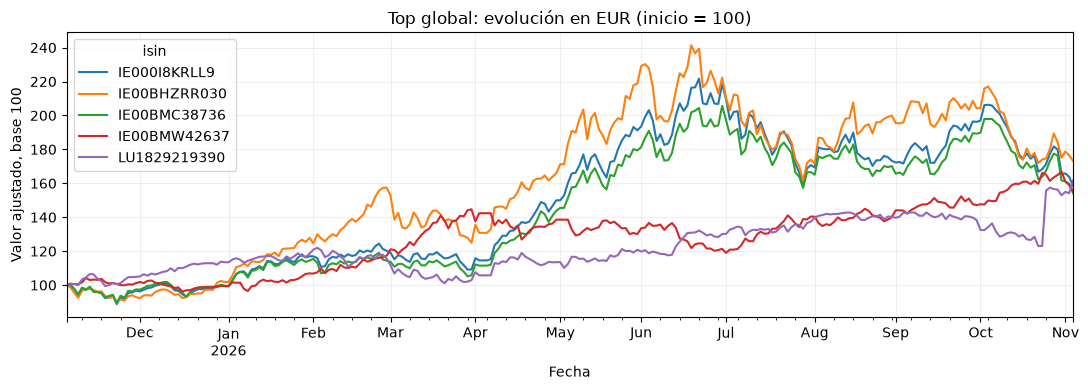

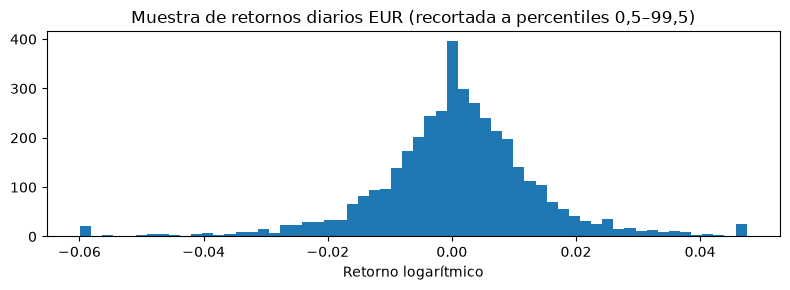

In [3]:
show_eda(ROOT, "etf", RESULT)

## 3. Qué significa «sector» en un fondo

Se usa la categoría publicada del fondo: renta variable global, bonos, tecnología, etc.
Un fondo diversificado no se fuerza a pertenecer a un solo sector corporativo.
Solo si falta esa clasificación se agrupan trayectorias mediante clustering (mínimo
4 activos y 60 observaciones comunes). El resultado se llama «grupo estadístico»,
sin atribuirle un sector económico inventado. Las categorías conocidas se conservan.


## 4. Top 5 global y por sector/categoría

Orden: rentabilidad total de los últimos **12 meses en EUR**, con idéntica fecha de referencia.
Si hay menos de cinco activos elegibles se muestran los que existan. Acciones, fondos y ETF
se clasifican por separado. Los activos sin datos suficientes siguen visibles en el informe de cobertura.


In [4]:
show_rankings(RESULT)

### Top 5 global por rentabilidad a un año en EUR

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | IE00BHZRR030 | FTSE Korea USD (Acc) | 73.10% |
| 2 | LU1829219390 | EURO STOXX Banks EUR (Acc) | 61.73% |
| 3 | IE000I8KRLL9 | MSCI Global Semiconductors USD (Acc) | 58.42% |
| 4 | IE00BMW42637 | MSCI Europe Energy EUR (Acc) | 55.50% |
| 5 | IE00BMC38736 | Semiconductor USD (Acc) | 54.21% |

### Top 5 por sector o categoría

**Across Different Sectors**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | IE00BYYHSQ67 | MSCI World Quality Dividend USD (Dist) | 28.71% |
| 2 | IE00BYYHSM20 | MSCI Europe Quality Dividend EUR (Dist) | 21.50% |
| 3 | IE000OEF25S1 | MSCI World Equal Weight (USD) Acc | 19.43% |
| 4 | LU1681048804 | S&P 500 EUR (Acc) | 16.81% |
| 5 | LU0322253906 | MSCI Europe Small Cap USD (Acc) | 16.69% |

**Aviation & Aeronautics**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | IE000YU9K6K2 | Space Innovators USD (Acc) | 10.87% |
| 2 | IE000OJ5TQP4 | Future of Defence USD (Acc) | 6.99% |

**Banking & Finance**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | LU1829219390 | EURO STOXX Banks EUR (Acc) | 61.73% |
| 2 | DE000A0F5UJ7 | STOXX 600 Banks EUR (Dist) | 29.80% |
| 3 | DE000A0H08K7 | STOXX 600 Insurance EUR (Dist) | 24.56% |
| 4 | IE00BMDKNW35 | Crypto & Blockchain Innovators USD (Acc) | -38.48% |

**Biotechnology**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | IE00BYXG2H39 | NASDAQ USD Biotechnology USD (Acc) | 42.13% |

... (19 outputs left out)

**Real Estate**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | IE00B1FZS350 | Developed Markets Property Yield USD (Dist) | 9.41% |

**Stocks (sin sector específico)**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | IE00BHZRR030 | FTSE Korea USD (Acc) | 73.10% |
| 2 | IE000I8KRLL9 | MSCI Global Semiconductors USD (Acc) | 58.42% |
| 3 | IE00BYPLS672 | Cyber Security USD (Acc) | 49.59% |
| 4 | IE00082MOBL9 | European SuperDividend EUR (Dis) | 46.39% |
| 5 | IE00BLPK3577 | Cybersecurity USD (Acc) | 43.18% |

**Telecommunication**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | IE00B3VSSL01 | Technology S&P US Select Sector USD (Acc) | 18.08% |
| 2 | LU1681038243 | NASDAQ 100 EUR (Acc) | 14.20% |

**Vehicles**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | IE00BGL86Z12 | Electric Driving Tech USD (Acc) | 24.68% |